![Alt text](https://imgur.com/orZWHly.png=80)
source: @allison_horst https://github.com/allisonhorst/penguins

You have been asked to support a team of researchers who have been collecting data about penguins in Antartica! The data is available in csv-Format as `penguins.csv`

**Origin of this data** : Data were collected and made available by Dr. Kristen Gorman and the Palmer Station, Antarctica LTER, a member of the Long Term Ecological Research Network.

**The dataset consists of 5 columns.**

Column | Description
--- | ---
culmen_length_mm | culmen length (mm)
culmen_depth_mm | culmen depth (mm)
flipper_length_mm | flipper length (mm)
body_mass_g | body mass (g)
sex | penguin sex

Unfortunately, they have not been able to record the species of penguin, but they know that there are **at least three** species that are native to the region: **Adelie**, **Chinstrap**, and **Gentoo**.  Your task is to apply your data science skills to help them identify groups in the dataset!

In [67]:
# Import Required Packages
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Loading and examining the dataset
penguins_df = pd.read_csv("penguins.csv")
print(penguins_df.info())
penguins_df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 332 entries, 0 to 331
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   culmen_length_mm   332 non-null    float64
 1   culmen_depth_mm    332 non-null    float64
 2   flipper_length_mm  332 non-null    float64
 3   body_mass_g        332 non-null    float64
 4   sex                332 non-null    object 
dtypes: float64(4), object(1)
memory usage: 13.1+ KB
None


,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,39.1,18.7,181.0,3750.0,MALE
1,39.5,17.4,186.0,3800.0,FEMALE
2,40.3,18.0,195.0,3250.0,FEMALE
3,36.7,19.3,193.0,3450.0,FEMALE
4,39.3,20.6,190.0,3650.0,MALE


In [68]:
# Sklearn requires Numeric data with no Missing values this means we need to run preprocessing and create dummy variables for sex
dummies = pd.get_dummies(penguins_df['sex'], drop_first=True)
penguins_df = pd.concat([penguins_df, dummies], axis=1).drop('sex', axis=1).astype('float')
penguins_df.dtypes

culmen_length_mm     float64
culmen_depth_mm      float64
flipper_length_mm    float64
body_mass_g          float64
MALE                 float64
dtype: object

In [69]:
# Now we need to standardise the data to make sure its ready for the K-means algo
scaler = StandardScaler()
penguins_scaled = scaler.fit_transform(penguins_df.values)

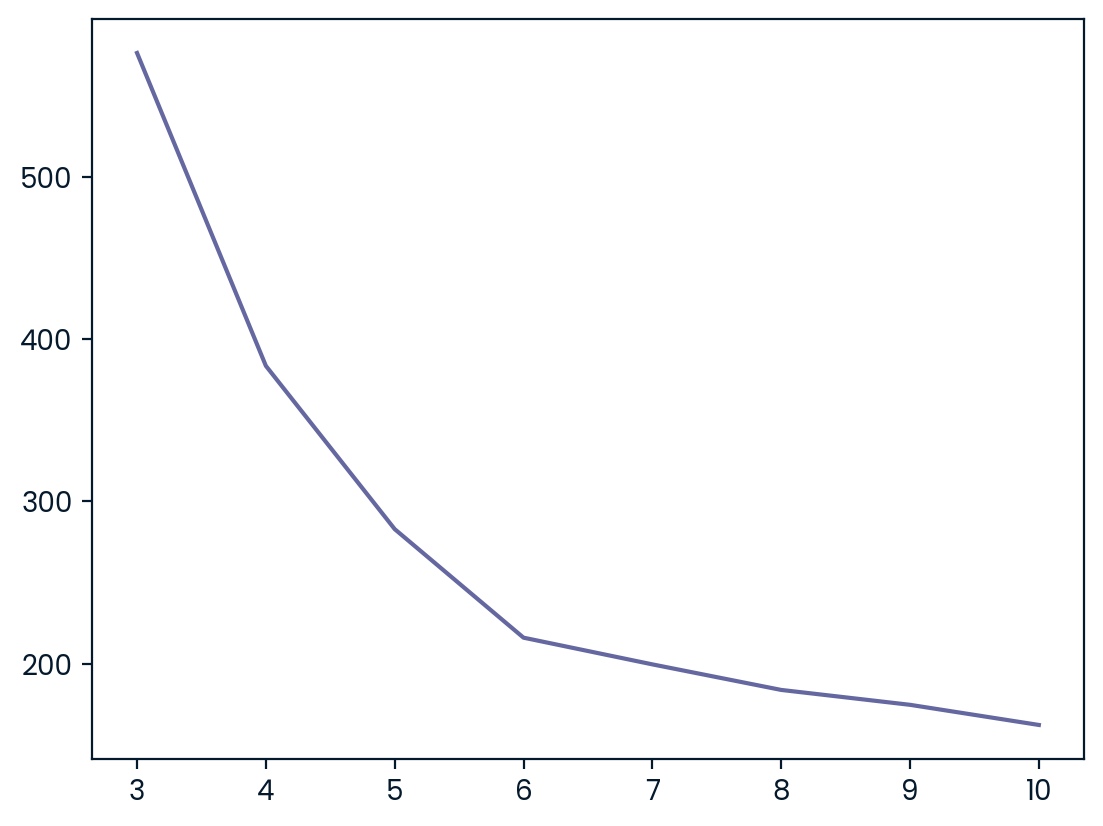

In [70]:
# Now we need to find the best number of centroids for reducing inertia 
inertias = []
ks = range(3,11)

for k in ks:
    km = KMeans(n_clusters=k).fit(penguins_scaled)
    inertias.append(km.inertia_)

plt.plot(ks, inertias)


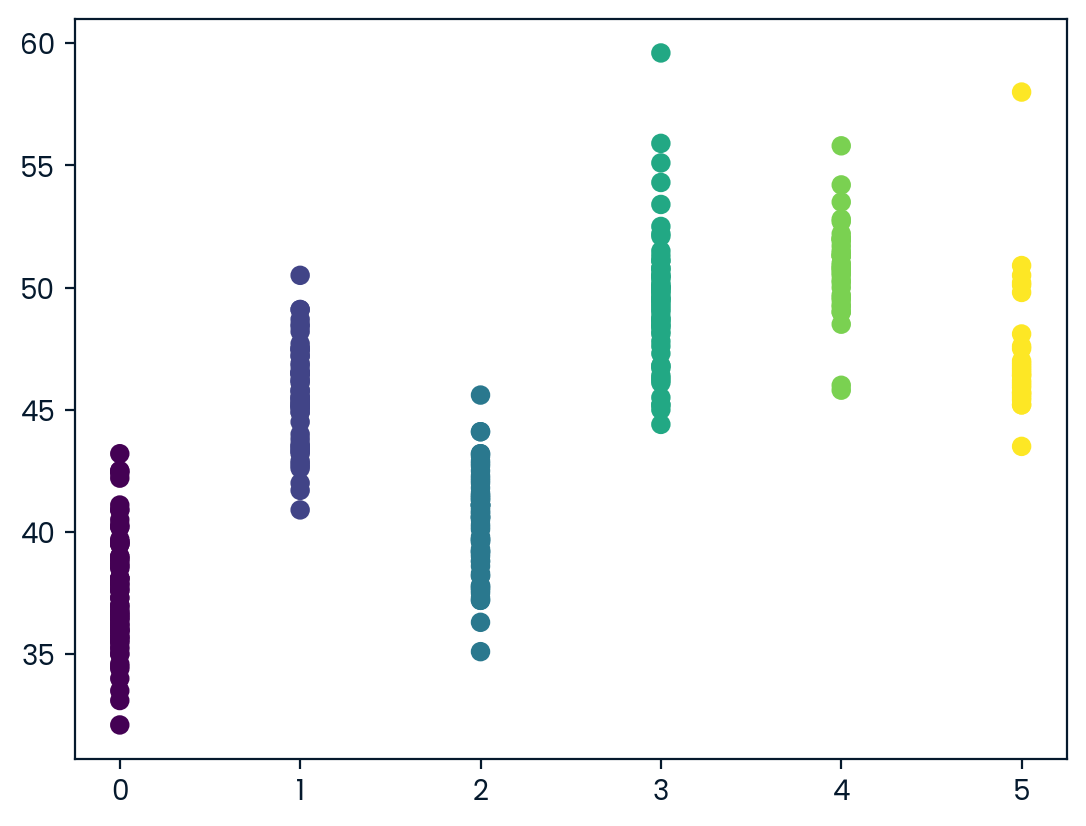

In [71]:
# Now we need to fit the KMeans algo with k=6 and predict the data
clusters = KMeans(n_clusters=6).fit_predict(penguins_scaled)

# Now I need to add the clusters to the penguin dataframe
penguins_df['cluster'] = clusters

plt.scatter(penguins_df['cluster'], penguins_df['culmen_length_mm'], c=penguins_df['cluster'])
plt.show()

In [72]:


# Now we create a Dataframe with an index of cluster values and the mean of their variables
stat_penguins = penguins_df.groupby('cluster').mean()
stat_penguins

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,MALE
cluster,,,,,
0,37.580769,17.575641,187.666667,3363.141026,0.0
1,45.563793,14.237931,212.706897,4679.741379,0.0
2,40.315714,19.011429,192.242857,4034.642857,1.0
3,49.473770,15.718033,221.540984,5484.836066,1.0
4,50.805556,19.305556,199.666667,3952.083333,1.0
5,47.310345,17.706897,192.758621,3569.827586,0.0
